# Classical ML Baselines (Before Deep Learning)

Before building deep learning models, we test **three classical ML models** on `RML2016.10a`.

**Key idea:** Raw I/Q waves shift in time and phase, so classical ML struggles on raw numbers. Instead, we summarize each signal into a few simple features (amplitude, phase changes, and frequency spread) and feed those to:
1. **Logistic Regression** — simple linear baseline.
2. **Random Forest** — strong tree-based model.
3. **HistGradientBoosting** — fast boosted trees (usually the strongest classical model on tabular features).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_rml2016a, build_arrays

SEED = 42
data = load_rml2016a(str(PROJECT_ROOT / "data" / "raw" / "RML2016.10a_dict.pkl"))
X_raw, y, snrs, class_names = build_arrays(data)
print("Loaded:", X_raw.shape, "| Classes:", len(class_names))

Loaded: (220000, 2, 128) | Classes: 11


## 1. Extract Simple Signal Features
We turn each `(2, 128)` signal into 12 summary numbers capturing **amplitude**, **phase changes**, and **frequency spectrum**.

In [2]:
def extract_features(X):
    I, Q = X[:, 0, :], X[:, 1, :]
    sig = I + 1j * Q

    amp = np.abs(sig)
    amp_mean = amp.mean(axis=1)
    amp_std = amp.std(axis=1)
    amp_max = amp.max(axis=1)
    amp_norm = (amp - amp_mean[:, None]) / (amp_std[:, None] + 1e-8)
    amp_kurt = (amp_norm ** 4).mean(axis=1)

    # Instantaneous frequency (phase difference between consecutive samples)
    dphase = np.angle(sig[:, 1:] * np.conj(sig[:, :-1]))
    dphase_mean = dphase.mean(axis=1)
    dphase_std = dphase.std(axis=1)
    dphase_abs_mean = np.abs(dphase).mean(axis=1)

    # Frequency spectrum (FFT magnitude)
    fft_mag = np.abs(np.fft.fft(sig, axis=1))
    fft_prob = fft_mag / (fft_mag.sum(axis=1, keepdims=True) + 1e-8)
    spec_max = fft_mag.max(axis=1) / (fft_mag.mean(axis=1) + 1e-8)
    spec_entropy = -(fft_prob * np.log(fft_prob + 1e-12)).sum(axis=1)

    # Energy & I/Q balance
    energy = (I ** 2 + Q ** 2).mean(axis=1)
    iq_ratio = I.std(axis=1) / (Q.std(axis=1) + 1e-8)
    iq_corr = (I * Q).mean(axis=1) / (I.std(axis=1) * Q.std(axis=1) + 1e-8)

    return np.column_stack([
        amp_mean, amp_std, amp_max, amp_kurt,
        dphase_mean, dphase_std, dphase_abs_mean,
        spec_max, spec_entropy, energy, iq_ratio, iq_corr
    ])

X_feat = extract_features(X_raw)
print("Feature matrix shape:", X_feat.shape)

Feature matrix shape: (220000, 12)


## 2. Leakage-Free Stratified Split (70% Train / 15% Val / 15% Test)
We stratify by both **modulation class and SNR** so every split has the exact same balance.

In [3]:
strat_key = y * 100 + (snrs + 20)

X_train, X_temp, y_train, y_temp, snr_train, snr_temp = train_test_split(
    X_feat, y, snrs, test_size=0.30, random_state=SEED, stratify=strat_key
)
strat_temp = y_temp * 100 + (snr_temp + 20)
X_val, X_test, y_val, y_test, snr_val, snr_test = train_test_split(
    X_temp, y_temp, snr_temp, test_size=0.50, random_state=SEED, stratify=strat_temp
)

print(f"Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")

Train: 154,000 | Val: 33,000 | Test: 33,000


## 3. Train & Compare Models

In [4]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=150, random_state=SEED),
}

results = []
preds = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    results.append({
        "Model": name,
        "Overall Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Macro-F1": round(f1_score(y_test, y_pred, average="macro"), 4),
        "Acc @ +10 dB": round(accuracy_score(y_test[snr_test == 10], y_pred[snr_test == 10]), 4),
    })

pd.DataFrame(results)

,Model,Overall Accuracy,Macro-F1,Acc @ +10 dB
0,Logistic Regression,0.4289,0.4186,0.6788
1,Random Forest,0.5108,0.5292,0.8061
2,HistGradientBoosting,0.5067,0.5221,0.7976


## 4. Accuracy vs. SNR & Confusion Matrix

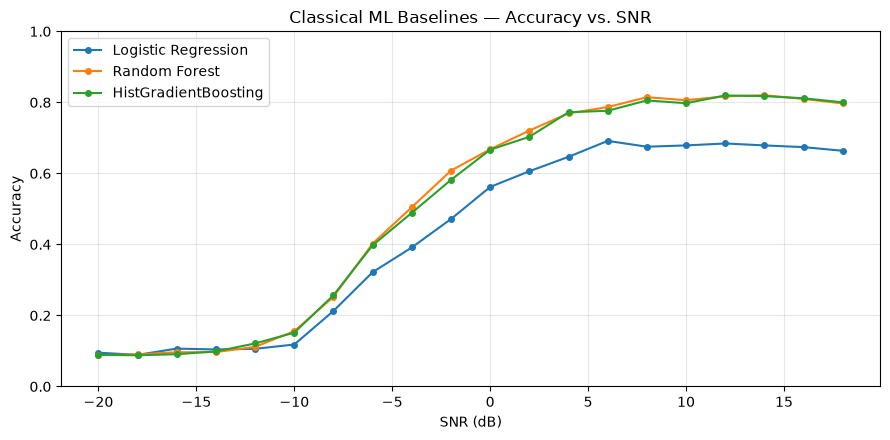

In [5]:
unique_snrs = sorted(np.unique(snr_test))

plt.figure(figsize=(9, 4.5))
for name, y_pred in preds.items():
    accs = [accuracy_score(y_test[snr_test == s], y_pred[snr_test == s]) for s in unique_snrs]
    plt.plot(unique_snrs, accs, marker="o", markersize=4, label=name)

plt.title("Classical ML Baselines — Accuracy vs. SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

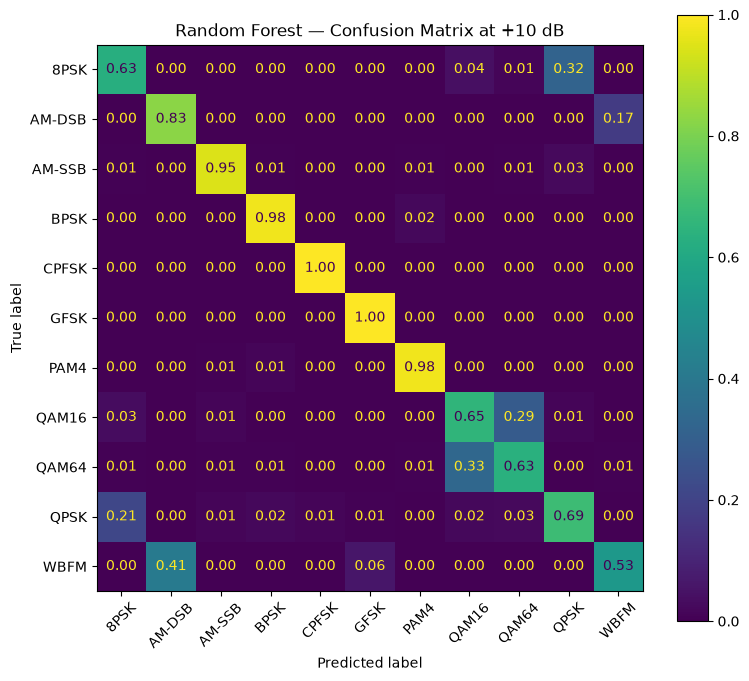

In [6]:
# Confusion matrix for the strongest classical model at +10 dB
best_name = max(results, key=lambda r: r["Overall Accuracy"])["Model"]
mask = snr_test == 10

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test[mask], preds[best_name][mask], display_labels=class_names,
    xticks_rotation=45, normalize="true", values_format=".2f", ax=ax
)
ax.set_title(f"{best_name} — Confusion Matrix at +10 dB")
plt.tight_layout()
plt.show()